对 [GPTtoLlama2](GPTtoLlama2.ipynb) 继续。考虑到运行时的便利，以及上个笔记本已经很长，重新分出来一个笔记本。

## Llama2toLlama3

在 OpenAI 发布 GPT-4 不久后，Meta AI 发布了 Llama3，一度以开源模型追上了闭源模型的性能，在 2024 年成为开源模型的首选。针对于 Llama2 到 Llama3 的升级，最大的改动是将 MHA（传统多头注意力） 更改成了 GQA（组查询注意力），以及在训练数据上的处理和模型规模上的扩大，最大的模型达到 405B。

Meta AI 开源提供了 8B 70B 405B 三个规模的模型，大多数情况下 70B 是性能和花费均衡的选择。notebook 最后我们会加载 8B 模型进行演示。

针对 Llama3 的新改动，基本上就围绕一个中心进行：**更长的上下文窗口**。如何让位置编码能够支持、以及如何节省内存，分别引出了 Scaling RoPE 和 GQA。

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/bonus/gpt-to-llama/gpt2-to-llama2-llama3.webp?1">

In [1]:
import torch
import torch.nn as nn

### 复用 Llama2 中实现的组件

正如上图，Llama3 的架构与 Llama2 差异很小。我们可以复用 [GPTtoLlama2](GPTtoLlama2.ipynb) 中实现的模块。

In [2]:
import os
import sys
import io
import nbformat
import types

def import_from_notebook():
    
    def import_definitions_from_notebook(fullname, names):
        """
        从当前目录下的 fullname.ipynb 中加载指定名字的定义。

        fullname: 不带 .ipynb 后缀的 notebook 文件名。
        names: 需要加载的函数名或类名字符串列表。
        """
        current_dir = os.getcwd()
        path = os.path.join(current_dir, fullname + ".ipynb")
        path = os.path.normpath(path)

        # 加载笔记本文件
        if not os.path.exists(path):
            raise FileNotFoundError(f"Notebook file not found at: {path}")
        with io.open(path, "r", encoding="utf-8") as f:
            nb = nbformat.read(f, as_version=4)

        # 动态创建一个模块对象，并把它注册到 Python 的模块缓存 sys.modules 中
        # 等价于创建了一个空的命名空间，名字是 fullname，作为执行 notebook 代码的命名空间
        mod = types.ModuleType(fullname)
        sys.modules[fullname] = mod
        # 要导入的函数用到的库的名字需要提前加载进模块中
        mod.__dict__.update({"torch": torch, "nn": nn})

        # 遍历所有 notebook 块
        for cell in nb.cells:
            if cell.cell_type == "code":
                cell_code = cell.source
                for name in names:
                    # 检查 code 块中是否包含定义函数或类的代码
                    # 如果出现，就执行整个代码单元
                    if f"def {name}" in cell_code or f"class {name}" in cell_code:
                        exec(cell_code, mod.__dict__)
        return mod

    fullname = "GPTtoLlama2"
    names = ["precompute_rope_params", "compute_rope", "SiLU", "FeedForward", "RMSNorm", "MultiHeadAttention", "RoPE"]

    return import_definitions_from_notebook(fullname, names)

为了便于使用，我们把这些函数一一从返回的 module 中取出来（实际上是在主空间创建一个指向这些函数的指针）。

In [3]:
imported_module = import_from_notebook()

# Llama3 更新了 RoPE，需要重写 precompute_rope_params
# precompute_rope_params = getattr(imported_module, "precompute_rope_params", None)
compute_rope = getattr(imported_module, "compute_rope", None)
SiLU = getattr(imported_module, "SiLU", None)
FeedForward = getattr(imported_module, "FeedForward", None)
RMSNorm = getattr(imported_module, "RMSNorm", None)

# Llama3 使用的是 GQA，MultiHeadAttention 只用于对比
MultiHeadAttention = getattr(imported_module, "MultiHeadAttention", None)
Llama2RoPE = getattr(imported_module, "RoPE", None)

### 增大 RoPE 的 $\theta_{base}$

我们在 Llama2 中引入了 RoPE 位置编码，其中唯一的超参数使用了默认值 10,000。RoPE 数学定义如下：

把 d 维向量分成 d/2 个二维子空间（即两个维度为一组），每个子空间用不同频率旋转。

$$
\theta_i = 10000^{-2i/d},\quad i=0,\dots,d/2-1
$$

这里 10000 是可以调的超参数，定义为 `theta_base` 。Llama2 使用默认值 10000，Llama3 增大为 500,000。

位置 m 的旋转矩阵为：

$$
R_{m,i}=
\begin{pmatrix}
\cos m\theta_i & -\sin m\theta_i\\
\sin m\theta_i & \cos m\theta_i
\end{pmatrix}
$$

$\theta_i$ 的几何意义是**不同的子空间的旋转速度**或角频率（位置推进 1，角度推进 $\theta_i$），可以类比成时钟，i 越小频率越大，转动速度快，即秒针。随着 i 变大转动速度变慢，即分针和时针。这样高频部分负责近距离关系（短波长），低频部分负责远距离关系（长波长）。

通过增大 `theta_base` 使得 RoPE 中不同维度对应的旋转波长被拉长，从而在**更长的序列**中避免位置编码重复（Llama3 使用 8192 的上下文窗口）。可以用下面的绘图感受 theta_base 变大给各个子空间角频率带来的影响。

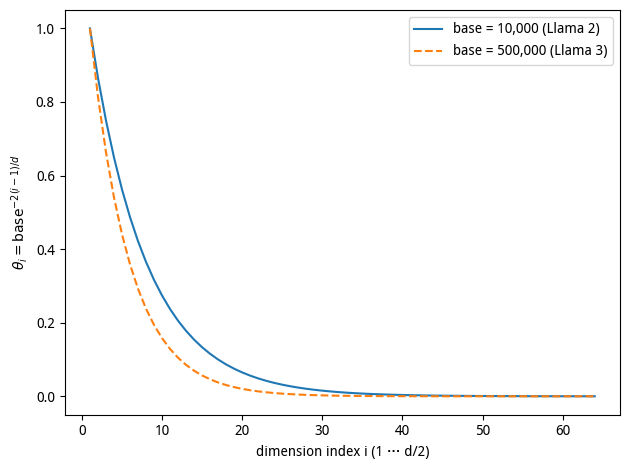

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'Microsoft YaHei', 'SimHei']
import torch
# 假设 emb_dim = 128，看 64 组时的变化
d = 128
i = torch.arange(1, d // 2 + 1)

base_llama2 = 10_000
base_llama3 = 500_000

theta_llama2 = base_llama2 ** (-2 * (i - 1) / d)
theta_llama3 = base_llama3 ** (-2 * (i - 1) / d)

plt.plot(i, theta_llama2, label="base = 10,000 (Llama 2)")
plt.plot(i, theta_llama3, label="base = 500,000 (Llama 3)", ls="--")
plt.xlabel("dimension index i (1 … d/2)")
plt.ylabel(r"$\theta_i = \mathrm{base}^{-2(i-1)/d}$")
plt.legend()
plt.tight_layout()

#### 为什么增大 theta_base 可以支持模型使用更大的上下文窗口？

对于频率 $\theta_i$，旋转角度随位置 $m$ 线性增加。当角度增加 $2\pi$ 时，旋转回到原点，位置编码出现重复。这个周期就是**波长**：

$$
\lambda_i = \frac{2\pi}{\theta_i} = 2\pi \cdot \text{base}^{\frac{2(i-1)}{d}}
$$

可以看到：

- **base 越大，$\lambda_i$ 越长**。
- 特别是最低频的维度（$i = d/2$），其波长近似为：
  $$
  \lambda_{\max} \approx 2\pi \cdot \text{base}
  $$
  也就是说，**最大可区分的位置范围与 base 成正比**。

RoPE 用多个频率的组合来编码位置。如果序列长度 $L$ 超过了某个维度的波长，那么该维度的旋转就会开始重复，不同位置可能得到完全相同的角度（模 $2\pi$），导致模型无法区分它们。

- 高频维度波长很短，在长序列中很快重复，但它们负责捕捉**局部**位置关系。
- 低频维度波长很长，负责捕捉**全局**位置关系。如果最低频维度的波长不够长，那么当序列很长时，全局位置编码也会重复，模型就彻底分不清远距离位置了。

因此，要支持长度 $L$ 的上下文，必须保证最低频维度的波长 $\lambda_{\max} > L$。而 $\lambda_{\max} \propto \text{base}$，所以增大 base 就能直接扩展可唯一编码的最大长度。

- Llama 2：`base = 10,000`，最低频波长约 $2\pi \times 10000 \approx 62,800$。
- Llama 3：`base = 500,000`，最低频波长约 $2\pi \times 500000 \approx 3,140,000$。

虽然 Llama 2 的波长理论上也大于 4096，但实际中位置编码的区分度会随着接近波长而下降，而且模型训练时见过的长度有限。增大 base 让低频维度的波长远远超过目标上下文长度（8192），从而在**训练和推理时都能更稳定地编码长距离位置**。

简单说就是：

**更大的 base → 所有频率 $\theta_i$ 变小 → 波长 $\lambda_i$ 变长 → 最低频维度的波长正比于 base → 可唯一编码的最大位置范围扩大 → 支持更长的上下文窗口。**

### RoPE Scaling

我们通过引入 `freq_config` 来进行 RoPE Scaling，这个操作在 Llama3.1 和 Llama3.2 中才使用，是使不同子空间的旋转频率不要和之前的 RoPE 一样，把所有频率统一缩放，而是按波长分段处理。目的是：**在扩展长上下文的同时，尽量不破坏模型原有的短距离/局部位置分辨能力。**

#### Scaling 数学公式

在模型设置中：

```python
freq_config = {
    "factor": s,    # 对模型能够扩展的上下文倍数的期望
    "low_freq_factor": f_low,
    "high_freq_factor": f_high,
    "original_context_length": L0,
}
```

通常：

- `factor` 是上下文扩展倍数，例如预训练时数据使用 8192 的上下文长度，factor 取 8 则期望模型在推理时能够处理 65536 的上下文。
- `low_freq_factor` 和 `high_freq_factor` 用来定义低频和高频的边界，用和原始上下文长度的倍数关系表示。
- `original_context_length` 是原始训练上下文长度，例如 8192。

定义两个波长阈值：

$$
\lambda_{\text{low}} = \frac{L_0}{f_{\text{low}}}
$$

$$
\lambda_{\text{high}} = \frac{L_0}{f_{\text{high}}}
$$

因为 $f_{\text{low}} < f_{\text{high}}$，所以：

$$
\lambda_{\text{low}} > \lambda_{\text{high}}
$$

对每个原始频率 $\theta_i$ 计算波长：

$$
\lambda_i = \frac{2\pi}{\theta_i}
$$

接下来做**高频保留，低频缩放，中频平滑过渡（$\alpha_i 与 \theta_i 线性关系$）**。Llama 3 RoPE scaling 对每个逆频率的修改是：

$$
\theta_i' =
\begin{cases}
\dfrac{\theta_i}{s},
& \lambda_i > \lambda_{\text{low}} \\[6pt]
(1-\alpha_i)\dfrac{\theta_i}{s} + \alpha_i \theta_i,
& \lambda_{\text{high}} \le \lambda_i \le \lambda_{\text{low}} \\[6pt]
\theta_i,
& \lambda_i < \lambda_{\text{high}}
\end{cases}
$$

其中：

$$
\lambda_i = \frac{2\pi}{\theta_i}
$$

$$
\lambda_{\text{low}} = \frac{L_0}{f_{\text{low}}},
\quad
\lambda_{\text{high}} = \frac{L_0}{f_{\text{high}}}
$$

$$
\alpha_i =
\frac{
L_0 / \lambda_i - f_{\text{low}}
}{
f_{\text{high}} - f_{\text{low}}
}
$$

然后用新的 $\theta_i'$ 计算角度：

$$
\phi_{m,i} = m \theta_i'
$$


In [5]:
# 这里就不像 GPTtoLlama2 中写成一个单独类型（一般实现是像 GPTtoLlama2 这样的）节省内存
# 后面将使用另一种方法同样达到节省内存的效果：cos sin 在注意力的 forward 中作为参数传入
def precompute_rope_params(head_dim, theta_base=10_000, context_length=4096, freq_config=None):
    assert head_dim % 2 == 0, "Embedding dimension must be even"
    
    # 计算各个子空间的角频率
    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    
    # 进行 RoPE Scaling
    if freq_config is not None:
        # 先根据 config 计算两个边界波长
        low_freq_wavelen = freq_config["original_context_length"] / freq_config["low_freq_factor"]
        high_freq_wavelen = freq_config["original_context_length"] / freq_config["high_freq_factor"]
        
        # 将角频率换算为波长
        wavelen = 2 * torch.pi / inv_freq
        
        # 对低频进行缩放
        inv_freq_llama = torch.where(
            wavelen > low_freq_wavelen, inv_freq / freq_config["factor"], inv_freq
        )
        # 对中频进行平滑化，保留高频不变
        smooth_factor = (freq_config["original_context_length"] / wavelen - freq_config["low_freq_factor"]) / (
            freq_config["high_freq_factor"] - freq_config["low_freq_factor"]
        )
        smoothed_inv_freq = (
            (1 - smooth_factor) * (inv_freq / freq_config["factor"]) + smooth_factor * inv_freq
        )
        is_medium_freq = (wavelen <= low_freq_wavelen) & (wavelen >= high_freq_wavelen)
        inv_freq_llama = torch.where(is_medium_freq, smoothed_inv_freq, inv_freq_llama)
        
        # 覆盖原来计算的角频率
        inv_freq = inv_freq_llama
    
    # 生成位置索引
    positions = torch.arange(context_length)
    # 用广播机制，计算角度表
    angles = positions.unsqueeze(1) * inv_freq.unsqueeze(0)  # (context_length, head_dim // 2)
    # 扩展到 head_dim 维度，直接复制一份并 concat，与 Llama2 分组一致
    angles = torch.cat([angles, angles], dim=1)  # (context_length, head_dim)
    # 计算 sin cos
    cos = torch.cos(angles)
    sin = torch.sin(angles)

    return cos, sin

RoPE Scaling 相当于只改变了 cos sin 的取值，并没有改变其作用于向量的操作。所以在使用时和 Llama2 中完全一致，可以复用 compute_rope 函数。

In [6]:
# 设置参数
llama_2_context_len = 4096
llama_3_context_len = 8192

llama_2_theta_base = 10_000
llama_3_theta_base = 500_000

batch_size = 2
num_heads = 4
head_dim = 16

# 计算 cos sin，相当于实例化
cos, sin = precompute_rope_params(
    head_dim=head_dim,
    theta_base=llama_3_theta_base,
    context_length=llama_3_context_len
)

# 随机生成 Q K 矩阵
torch.manual_seed(123)
queries = torch.randn(batch_size, num_heads, llama_3_context_len, head_dim)
keys = torch.randn(batch_size, num_heads, llama_3_context_len, head_dim)

# 使用 RoPE 位置编码（旋转操作）
queries_rot = compute_rope(queries, cos, sin)
keys_rot = compute_rope(keys, cos, sin)

#### 为什么需要 RoPE Scaling

**一般方法是对所有频率“一刀切”地缩放，能扩展上下文，但牺牲局部位置分辨率。Llama 3.1/3.2 的分段缩放只压低低频、保留高频、中频平滑过渡，因此在长上下文能力和短距离精度之间取得了更好的平衡。**

RoPE 用旋转角度表示位置：

$$
\text{angle}_{t,i}=t \cdot \text{inv\_freq}_i
$$

其中：

$$
\text{inv\_freq}_i = \frac{1}{\theta_{\text{base}}^{2i/d}}
$$

- `inv_freq` 越大，波长越短，旋转越快，负责区分近距离 token；  
- `inv_freq` 越小，波长越长，旋转越慢，负责区分远距离 token。

模型预训练时只见过有限上下文。如果直接外推，位置 $t$ 会远超训练范围，很多角度变成模型没见过的值，注意力就会失效。所以需要调整 `inv_freq`，让长位置上的旋转不要“过强”或“过乱”。

把 `theta_base` 从 10000 调到 500000 等，会让所有 `inv_freq` 变小。效果类似全局降低频率，会牺牲高频部分的局部分辨率。

Llama 3.1 / 3.2 基于波长对原始公式进行分段缩放。先算每个频率分量的波长：

$$
\text{wavelen} = \frac{2\pi}{\text{inv\_freq}}
$$

然后按波长分三段：

| 频段 | 波长 | 处理方式 |
|---|---|---|
| 低频 | 波长很长 | `inv_freq / factor`，进一步降低频率，让旋转更慢，支持更长上下文 |
| 高频 | 波长很短 | 保持不变，保留局部位置分辨率 |
| 中频 | 中间过渡 | 在“缩放后”和“原始”之间做平滑插值 |

带来了下面的好处：

1. 长上下文外推能力更强：低频被进一步降低，波长变长，旋转速度变慢。如果位置 $t$ 很大，角度也不会增长得太快，模型能处理更远的位置。
2. 保留短距离/局部位置分辨率：高频不缩放，相邻 token 之间的旋转差异仍然明显。
3. 中频平滑过渡，避免突变：平滑的旋转可以增强训练的稳定性，保护注意力结构。
4. 实现简单，可在推理时生效：只是对预计算的 `inv_freq` 做调整，不需要改变模型结构。

下面的代码通过绘图展示使用 Llama 3 RoPE Scaling 前后，逆频率（角频率）随维度索引的变化。

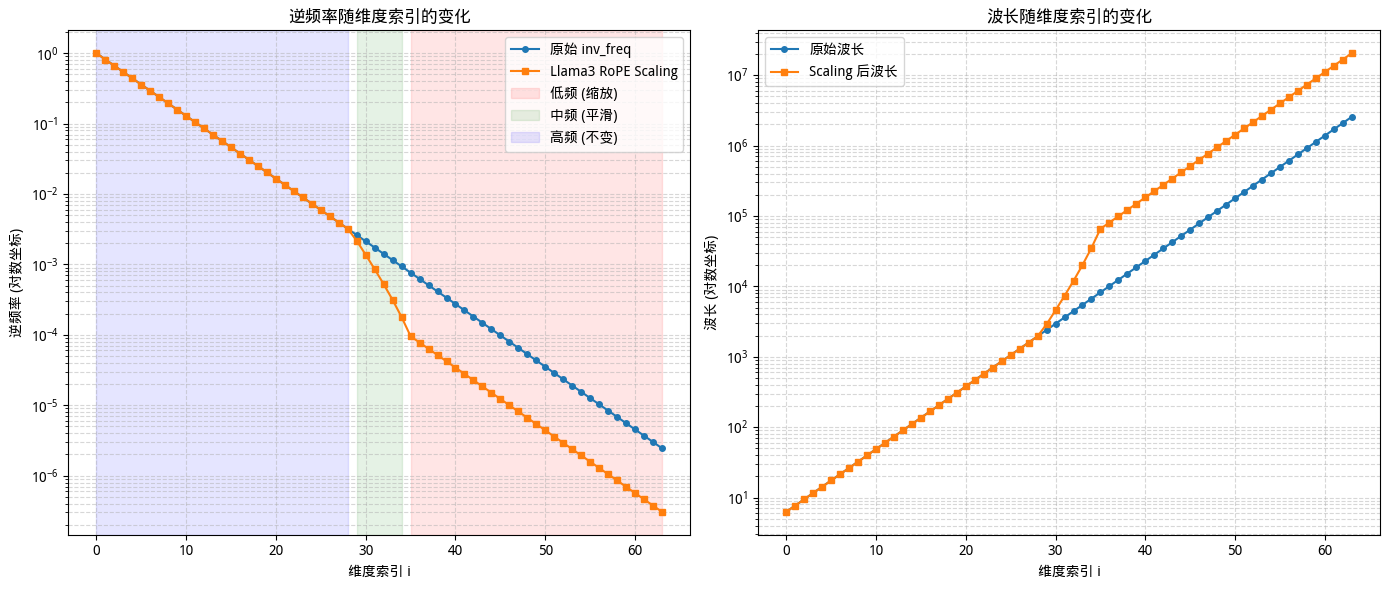

In [7]:
import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei']

def compute_inv_freq(head_dim, theta_base=10000.0, freq_config=None):
    """计算原始或经过 Llama 3 RoPE Scaling 后的逆频率"""
    # 原始逆频率
    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    
    if freq_config is not None:
        # 波长阈值
        low_freq_wavelen = freq_config["original_context_length"] / freq_config["low_freq_factor"]
        high_freq_wavelen = freq_config["original_context_length"] / freq_config["high_freq_factor"]
        
        wavelen = 2 * torch.pi / inv_freq
        
        # 低频：完全缩放
        inv_freq_llama = torch.where(
            wavelen > low_freq_wavelen, inv_freq / freq_config["factor"], inv_freq
        )
        
        # 中频：平滑插值
        smooth_factor = (
            freq_config["original_context_length"] / wavelen - freq_config["low_freq_factor"]
        ) / (
            freq_config["high_freq_factor"] - freq_config["low_freq_factor"]
        )
        smoothed_inv_freq = (
            (1 - smooth_factor) * (inv_freq / freq_config["factor"]) + smooth_factor * inv_freq
        )
        
        # 判断中频范围
        is_medium_freq = (wavelen <= low_freq_wavelen) & (wavelen >= high_freq_wavelen)
        inv_freq_llama = torch.where(is_medium_freq, smoothed_inv_freq, inv_freq_llama)
        inv_freq = inv_freq_llama
    
    return inv_freq

# ================== 参数设置 ==================
head_dim = 128
theta_base = 500000.0          # Llama 3 常用值
context_length = 8192          # 原始上下文长度 L0
freq_config = {
    "factor": 8.0,             # 扩展倍数 s
    "low_freq_factor": 1.0,
    "high_freq_factor": 4.0,
    "original_context_length": 8192
}

# 计算逆频率
inv_freq_orig = compute_inv_freq(head_dim, theta_base, freq_config=None)
inv_freq_scaled = compute_inv_freq(head_dim, theta_base, freq_config=freq_config)

# 维度索引（0 到 head_dim/2 - 1）
indices = torch.arange(0, head_dim // 2)

# 计算波长，用于确定分段
wavelen_orig = 2 * torch.pi / inv_freq_orig
low_freq_wavelen = freq_config["original_context_length"] / freq_config["low_freq_factor"]
high_freq_wavelen = freq_config["original_context_length"] / freq_config["high_freq_factor"]

# 标记三个频段（基于原始波长）
low_mask = wavelen_orig > low_freq_wavelen
high_mask = wavelen_orig < high_freq_wavelen
medium_mask = (wavelen_orig <= low_freq_wavelen) & (wavelen_orig >= high_freq_wavelen)

# ================== 绘图 ==================
plt.figure(figsize=(14, 6))

# 子图1：逆频率对比（对数坐标）
plt.subplot(1, 2, 1)
plt.plot(indices, inv_freq_orig, label='原始 inv_freq', marker='o', markersize=4)
plt.plot(indices, inv_freq_scaled, label='Llama3 RoPE Scaling', marker='s', markersize=4)
plt.yscale('log')
plt.xlabel('维度索引 i')
plt.ylabel('逆频率 (对数坐标)')
plt.title('逆频率随维度索引的变化')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()

# 用背景色标出三个频段（仅示意，基于原始波长划分）
if low_mask.any():
    plt.axvspan(indices[low_mask].min().item(), indices[low_mask].max().item(),
                color='red', alpha=0.1, label='低频 (缩放)')
if medium_mask.any():
    plt.axvspan(indices[medium_mask].min().item(), indices[medium_mask].max().item(),
                color='green', alpha=0.1, label='中频 (平滑)')
if high_mask.any():
    plt.axvspan(indices[high_mask].min().item(), indices[high_mask].max().item(),
                color='blue', alpha=0.1, label='高频 (不变)')
plt.legend()

# 子图2：波长对比
plt.subplot(1, 2, 2)
plt.plot(indices, wavelen_orig, label='原始波长', marker='o', markersize=4)
plt.plot(indices, 2 * torch.pi / inv_freq_scaled, label='Scaling 后波长', marker='s', markersize=4)
plt.yscale('log')
plt.xlabel('维度索引 i')
plt.ylabel('波长 (对数坐标)')
plt.title('波长随维度索引的变化')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

### GQA 组查询注意力

实际上在 Llama2-70B 中 GQA 已经被引入。但 Llama3 把这一技术用到了所有大小的模型中，因此，从“各版本普遍具备 GQA”这个角度看，Llama 3 是一个转折点。所以我们在这里介绍 GQA。

Grouped-query Attention 可以被视为一种计算更简单，参数更少的多头注意力。因为随着上下文窗口的增加，注意力权重矩阵成平方关系增长，带来计算量和内存使用量的很大提升。同时，由于推理阶段 KV Cache 的引入，更长的上下文窗口将进一步占用显存和计算量，在推理阶段降低 tok/sec 使模型输出变慢。

GQA 论文的核心发现之一是：多头注意力中，**不同 Key/Value 头之间存在较高冗余**。很多 K/V 头学到的表示高度相似，因此可以把它们分组、共享甚至平均合并，而模型性能下降很小。论文中有一个关键实验：把已经训练好的 MHA 模型的 K/V 头按组做均值池化，转成 GQA，然后只需要少量 uptrain，就能恢复到接近 MHA 的质量。

因此，可以把多个 Query 头分成一组，让组内共享同一对 Key/Value 头：Query 头数量保持不变，Key/Value 头数量减少。这样既保留了 Query 侧的多视角表达能力，又大幅减少了 K/V 投影参数和推理阶段的 KV Cache。Llama 3 采用 GQA，核心原因就是**长上下文推理时 KV Cache 已成为显存容量和显存带宽的主要瓶颈**。

#### GQA 数学定义

设：

- $h$：Query 头数量；
- $g$：Key/Value 头数量；
- $r = h / g$：每个 K/V 头被多少个 Query 头共享；
- $d_{\text{head}}$：单个注意力头的维度；
- $X \in \mathbb{R}^{B \times T \times d}$：输入。

MHA 中：
$$
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
$$
其中 $W_Q,W_K,W_V$ 都产生 $h$ 个头。

GQA 中：
$$
Q = XW_Q \in \mathbb{R}^{B \times T \times h \times d_{\text{head}}}
$$
$$
K = XW_K \in \mathbb{R}^{B \times T \times g \times d_{\text{head}}}
$$
$$
V = XW_V \in \mathbb{R}^{B \times T \times g \times d_{\text{head}}}
$$

也就是说，Query 仍然是 $h$ 个头，但 Key/Value 只有 $g$ 个头。第 $i$ 个 Query 头对应第
$$
j = \left\lfloor \frac{i}{r} \right\rfloor
$$
个 K/V 头。其注意力计算为：
$$
A_i = \operatorname{softmax}\left(\frac{Q_i K_j^T}{\sqrt{d_{\text{head}}}} + \text{mask}\right)
$$
$$
O_i = A_i V_j
$$
最后将所有 $O_i$ 拼接：
$$
O = \operatorname{Concat}(O_1,\dots,O_h)W_O
$$

当 $g=h$ 时，GQA 退化为 MHA；当 $g=1$ 时，GQA 退化为 MQA。Llama 3 8B 中，通常 $h=32$，$g=8$，即每 4 个 Query 头共享 1 组 K/V。

#### KV Cache 原理

自回归生成时，模型每次只生成一个新 token。但注意力需要当前 token 与历史所有 token 的 Key/Value 计算相似度。如果没有 KV Cache，每生成一步都要重新计算整个历史序列的 K 和 V，计算量会随上下文长度快速膨胀。

KV Cache 的做法是：在每一层中缓存历史 token 的 Key 和 Value。生成第 $t$ 个 token 时：

1. 只计算当前 token 的 $q_t,k_t,v_t$；
2. 将 $k_t,v_t$ 追加到缓存：
$$
K_{\text{cache}} \leftarrow [K_{\text{cache}}; k_t]
$$
$$
V_{\text{cache}} \leftarrow [V_{\text{cache}}; v_t]
$$
3. 用当前 $q_t$ 与整个 $K_{\text{cache}}$ 做注意力：
$$
o_t = \operatorname{softmax}\left(\frac{q_t K_{\text{cache}}^T}{\sqrt{d_{\text{head}}}}\right)V_{\text{cache}}
$$

这样每步只需计算新 token 的投影，并读取历史缓存，避免重复计算历史 K/V。代价是显存中需要长期保存 KV Cache。

KV Cache 大小可以估算为：
$$
\text{MHA Cache} = 2 \times B \times T \times L \times h \times d_{\text{head}} \times \text{bytes}
$$
$$
\text{GQA Cache} = 2 \times B \times T \times L \times g \times d_{\text{head}} \times \text{bytes}
$$
其中 $2$ 表示 Key 和 Value 两份，$B$ 是 batch size，$T$ 是上下文长度，$L$ 是层数，bytes 是每个元素的字节数，例如 FP16 为 2 字节。

因此，GQA 相对于 MHA 的 KV Cache 缩小比例为：
$$
\frac{g}{h}
$$

以 Llama 3 8B 为例，若 $h=32$，$g=8$，则 KV Cache 减少为原来的 $1/4$。在 FP16、batch size 为 1、上下文 8192 时，MHA 的 KV Cache 约为 4 GB，而 GQA 约为 1 GB。推理时每生成一个 token 都需要读取整个 KV Cache，因此 GQA 不仅节省显存，还显著降低显存带宽压力，提高 tok/sec 和可支持的并发 batch 数。

#### GQA 代码实现

在代码实现上，GQA 和 MHA 非常相似，只需要注意在计算注意力权重前，通过 `repeat_interleave` 让缩减后的 K V 矩阵和之前的 MHA 对齐即可。另外我们把 mask cos sin 都写入 forward 的参数中，这样只需要在最上层模块创建一份内存用于存值，就可以供所有注意力层使用，节省内存。

In [8]:
import math
from torch.nn import functional as F

class GroupedQueryAttention(nn.Module):
    # 新增：kv 组数，要求 num_heads 能够整除 num_kv_groups
    def __init__(self, d_in, d_out, num_heads, num_kv_groups, dtype=None):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        assert num_heads % num_kv_groups == 0, "num_heads must be divisible by num_kv_groups"  # NEW

        # 存储必要的变量
        self.d_out = d_out
        self.num_heads = num_heads  # 共有多少个注意力头
        self.head_dim = d_out // num_heads  # 每个头各自处理的向量的维度
        self.num_kv_groups = num_kv_groups  # 共有多少组
        self.group_size = num_heads // num_kv_groups    # 每组有多少个注意力头

        # 权重矩阵，K V 不再需要 dout 维度的输出
        self.W_key = nn.Linear(d_in, num_kv_groups * self.head_dim, bias=False, dtype=dtype)
        self.W_value = nn.Linear(d_in, num_kv_groups * self.head_dim, bias=False, dtype=dtype)
        self.W_query = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.out_proj = nn.Linear(d_out, d_out, bias=False, dtype=dtype)

    def forward(self, x, mask=None, cos=None, sin=None):
        b, num_tokens, d_in = x.shape

        # 注意力投影
        queries = self.W_query(x)  # (b, num_tokens, d_out)
        keys = self.W_key(x)      # (b, num_tokens, num_kv_groups * head_dim)
        values = self.W_value(x)  # (b, num_tokens, num_kv_groups * head_dim)

        # 分出各个注意力头
        queries = queries.reshape(b, num_tokens, self.num_heads, self.head_dim)
        keys = keys.reshape(b, num_tokens, self.num_kv_groups, self.head_dim)
        values = values.reshape(b, num_tokens, self.num_kv_groups, self.head_dim)

        # 转置把序列长度和头中向量维度放到后两维
        keys = keys.transpose(1, 2)  # (b, num_kv_groups, num_tokens, head_dim)
        values = values.transpose(1, 2)  # (b, num_kv_groups, num_tokens, head_dim)
        queries = queries.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)

        # 对 Q K 矩阵进行 RoPE 位置编码
        if cos is not None:
            keys = compute_rope(keys, cos, sin)
            queries = compute_rope(queries, cos, sin)

        # 复制 K V 保证与 Q 维度对齐
        # repeat_interleave 是“逐元素连续重复”，repeat 是“整体平铺复制”
        keys = keys.repeat_interleave(self.group_size, dim=1)  # (b, num_heads, num_tokens, head_dim)
        values = values.repeat_interleave(self.group_size, dim=1)  # (b, num_heads, num_tokens, head_dim)

        # 缩放点积注意力
        att = (queries @ keys.transpose(-2, -1)) * (1.0 / math.sqrt(keys.size(-1)))
        # 动态创建因果掩码。建议传入 mask（即不要进入下方的 if）
        if mask is None:
            mask = torch.triu(torch.ones(num_tokens, num_tokens, device=x.device, dtype=torch.bool), diagonal=1)
        att.masked_fill_(mask, -torch.inf)
        # 计算加权 value
        att = F.softmax(att, dim=-1)
        y = att @ values
        
        # 恢复形状
        y = y.transpose(1, 2).reshape(b, num_tokens, self.d_out)
        y = self.out_proj(y)
        
        return y

#### GQA 与 MHA 对比

下面是 GPT 和 Llama2 使用的多头注意力，我们打印出 K Q V 权重矩阵的形状。

In [9]:
# 模型超参数设定
batch_size = 1
context_len = 3000
max_context_len = 8192
embed_dim = 4096
num_heads = 32

head_dim = embed_dim // num_heads  # 128

example_batch = torch.randn((batch_size, context_len, embed_dim))

rope = Llama2RoPE(head_dim, context_length=max_context_len)
mha = MultiHeadAttention(
    d_in=embed_dim,
    d_out=embed_dim,
    context_length=max_context_len,
    num_heads=num_heads,
    rope = rope
)

mha(example_batch)

print("W_key:", mha.W_key.weight.shape)
print("W_value:", mha.W_value.weight.shape)
print("W_query:", mha.W_query.weight.shape)

W_key: torch.Size([4096, 4096])
W_value: torch.Size([4096, 4096])
W_query: torch.Size([4096, 4096])


如果使用 GQA，按照 Llama3 我们使用 8 个 kv-group，意味着每 4 个注意力头共用一个 K V 矩阵。则 K V 的权重矩阵应该小 4 倍。

In [10]:
gqa = GroupedQueryAttention(
    d_in=embed_dim,
    d_out=embed_dim,
    num_heads=num_heads,
    num_kv_groups=8,
)

gqa(example_batch)

print("W_key:", gqa.W_key.weight.shape)
print("W_value:", gqa.W_value.weight.shape)
print("W_query:", gqa.W_query.weight.shape)

W_key: torch.Size([1024, 4096])
W_value: torch.Size([1024, 4096])
W_query: torch.Size([4096, 4096])


另外，如果想用 GQA 实例化 MHA，只需要让 kv_groups 数量和注意力头的数量相同即可，即 1 个注意力头为 1 组。代码上就是 num_kv_groups == num_heads。

最后统计一下参数数量用于直观比较。

In [11]:
print("Total number of parameters:")

mha_total_params = sum(p.numel() for p in mha.parameters())
print(f"MHA: {mha_total_params:,}")

gqa_total_params = sum(p.numel() for p in gqa.parameters())
print(f"GQA: {gqa_total_params:,}")

# 及时释放内存
del mha
del gqa

Total number of parameters:
MHA: 67,108,864
GQA: 41,943,040


### 更新使用 GQA 的 Transformer 块

只需要把 MHA 更换为 GQA，同时在 forward 中保留 mask, cos, sin 的传参就可以。mask, cos, sin 我们只在顶层模块计算并保存。

In [12]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = GroupedQueryAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            num_heads=cfg["n_heads"],
            num_kv_groups=cfg["n_kv_groups"],
            dtype=cfg["dtype"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = RMSNorm(cfg["emb_dim"], eps=1e-5)
        self.norm2 = RMSNorm(cfg["emb_dim"], eps=1e-5)
    
    def forward(self, x, mask=None, cos=None, sin=None):
        # 注意力层
        shortcut = x
        x = self.norm1(x)
        x = self.att(x.to(torch.bfloat16), mask, cos, sin)   # [batch_size, num_tokens, emb_size]
        x = x + shortcut
        
        # FFN
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x.to(torch.bfloat16))
        x = x + shortcut
        
        return x

### 创建 Llama3 架构模块

在这一层计算并存储 mask, cos, sin。（实际上 mask 在顶层架构 forward 中每次调用都要计算一次，这里也可以和 cos sin 一样写到成员变量中，更加节省内存）其他与 GPT, Llama2 一致。

In [13]:
class Llama3Model(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # token 嵌入层
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"], dtype=cfg["dtype"])
        # Transformer 块
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )
        # 最后的 norm 以及线性投影层
        self.final_norm = RMSNorm(cfg["emb_dim"], eps=1e-5)
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False, dtype=cfg["dtype"])

        # 计算 cos sin RoPE 旋转矩阵并存储
        cos, sin = precompute_rope_params(
            head_dim=cfg["emb_dim"] // cfg["n_heads"],
            theta_base=cfg["rope_base"],
            context_length=cfg["context_length"],
            freq_config=cfg["rope_freq"]
        )
        # 注册进模型的参数表，能够跟随模型 to(device) 但不参与梯度运算
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        # 模型超参数配置
        self.cfg = cfg

    def forward(self, in_idx):
        tok_embeds = self.tok_emb(in_idx)
        x = tok_embeds  # (batch_size, num_tokens, embed_dim)

        num_tokens = x.shape[1]
        # 创建掩码布尔矩阵，需要指定 diagonal=1 不要包含主对角线
        mask = torch.triu(torch.ones(num_tokens, num_tokens, device=x.device, dtype=torch.bool), diagonal=1)
        
        for block in self.trf_blocks:
            x = block(x, mask, self.cos, self.sin)
            
        x = self.final_norm(x)
        logits = self.out_head(x.to(self.cfg["dtype"]))
        return logits

### 模型超参数设定

同时给出 Llama2-7B 和 Llama3-8B 的超参数配置。

In [14]:
LLAMA2_CONFIG_7B = {
    "vocab_size": 32_000,    # Vocabulary size
    "context_length": 4096,  # Context length
    "emb_dim": 4096,         # Embedding dimension
    "n_heads": 32,           # Number of attention heads
    "n_layers": 32,          # Number of layers
    "hidden_dim": 11_008,    # Size of the intermediate dimension in FeedForward
    "dtype": torch.bfloat16  # Lower-precision dtype to reduce memory usage
}

In [15]:
LLAMA3_CONFIG_8B = {
    "vocab_size": 128_256,   # NEW: Larger vocabulary size
    "context_length": 8192,  # NEW: Larger context length
    "emb_dim": 4096,         # Embedding dimension
    "n_heads": 32,           # Number of attention heads
    "n_layers": 32,          # Number of layers
    "hidden_dim": 14_336,    # NEW: Larger size of the intermediate dimension in FeedForward
    "n_kv_groups": 8,        # NEW: Key-Value groups for grouped-query attention
    "rope_base": 500_000.0,  # NEW: The base in RoPE's "theta" was increased to 500_000
    "rope_freq": None,       # NEW: Additional configuration for adjusting the RoPE frequencies
    "dtype": torch.bfloat16  # Lower-precision dtype to reduce memory usage
}

现在可以创建 Llama3-8B 模型，需要约 34GB 内存。（Llama2-7B 需要约 26GB）

In [16]:
model = Llama3Model(LLAMA3_CONFIG_8B)

同样，我们可以统计总的参数数量，大致为 8B。

In [17]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 8,030,261,248


可以像在 Llama2 中一样估计模型占用的内存大小。

In [18]:
def calc_model_memory_size(model, input_dtype=torch.float32):
    total_params = 0    # 计算模型中所有参数的数量
    total_grads = 0     # BP 算法需要额外保存梯度值，故需计算模型中所有需要梯度的参数的数量
    for param in model.parameters():
        # param 都是 torch 张量，用 numel 统计数字数量
        param_size = param.numel()
        total_params += param_size
        # 是否保存梯度
        if param.requires_grad:
            total_grads += param_size

    # 计算所有 buffer（模型的 non-params 存储的地方）存的数字数量
    total_buffers = sum(buf.numel() for buf in model.buffers())

    # Size in bytes = (Number of elements) * (Size of each element in bytes)
    # 假定所有数据都已经使用相同的 dtype
    element_size = torch.tensor(0, dtype=input_dtype).element_size()
    total_memory_bytes = (total_params + total_grads + total_buffers) * element_size

    # 转换单位，用 1024 进制
    total_memory_gb = total_memory_bytes / (1024**3)
    return total_memory_gb

print(f"float32 (PyTorch default): {calc_model_memory_size(model, input_dtype=torch.float32):.2f} GB")
print(f"bfloat16: {calc_model_memory_size(model, input_dtype=torch.bfloat16):.2f} GB")

float32 (PyTorch default): 59.84 GB
bfloat16: 29.92 GB


可以把模型移动至 GPU 或 mps 上。运行前先确认有足够的显存/内存。经过在 AutoDL 上实测，需要 15704MB 的显存装下模型。上面计算的是训练阶段最少需要的显存，我们直接加载预训练权重，不需要那么多。

In [19]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model.to(device)

Llama3Model(
  (tok_emb): Embedding(128256, 4096)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): GroupedQueryAttention(
        (W_key): Linear(in_features=4096, out_features=1024, bias=False)
        (W_value): Linear(in_features=4096, out_features=1024, bias=False)
        (W_query): Linear(in_features=4096, out_features=4096, bias=False)
        (out_proj): Linear(in_features=4096, out_features=4096, bias=False)
      )
      (ff): FeedForward(
        (fc1): Linear(in_features=4096, out_features=14336, bias=False)
        (fc2): Linear(in_features=4096, out_features=14336, bias=False)
        (fc3): Linear(in_features=14336, out_features=4096, bias=False)
        (silu): SiLU()
      )
      (norm1): RMSNorm()
      (norm2): RMSNorm()
    )
    (1): TransformerBlock(
      (att): GroupedQueryAttention(
        (W_key): Linear(in_features=4096, out_features=1024, bias=False)
        (W_value): Linear(in_features=4096, out_features=1024, bias=False)
        (W_qu

### Tokenizer

Llama2 使用了 Google 的 [SentencePiece](https://github.com/google/sentencepiece) tokenizer 替换 GPT 中使用的 OpenAI 的 BPE tokenizer，实现于 [Tiktoken](https://github.com/openai/tiktoken) 库。而 Llama3 又用回了 BPE tokenizer，更具体一些是在 GPT-4 tokenizer 的基础上用了更大的词表。

因为使用的是 OpenAI 的 Tiktoken，Llama 无法像 GPT 一样简单地通过 `enc = tiktoken.get_encoding("gpt2")` 创建一个 tokenizer，所以需要手动实现一些 BPE 以外的模块，如 BPE合并词表、分词正则模式、特殊 token 映射。我们**下载的开源数据只有 BPE合并词表**，其他部分的实现可以参考 Meta AI 官方仓库中的代码 [here](https://github.com/meta-llama/llama3/blob/main/llama/tokenizer.py)。

下面的代码是 rasbt 重写的 Llama3 tokenizer，保持相似的代码行为并增加可读性。注意这段重写的代码和官方并不完全一致，建立在我们的笔记本的使用场景**不涉及工具调用**的基础上。

In [20]:
from pathlib import Path

import tiktoken
from tiktoken.load import load_tiktoken_bpe


class Tokenizer:
    """Thin wrapper around tiktoken that keeps track of Llama-3 special IDs."""
    def __init__(self, model_path):
        if not os.path.isfile(model_path):
            raise FileNotFoundError(model_path)

        mergeable = load_tiktoken_bpe(model_path)

        # hard-coded from Meta's tokenizer.json
        self.special = {
            "<|begin_of_text|>": 128000,
            "<|end_of_text|>": 128001,
            "<|start_header_id|>": 128006,
            "<|end_header_id|>": 128007,
            "<|eot_id|>": 128009,
        }
        self.special.update({f"<|reserved_{i}|>": 128002 + i
                             for i in range(256)
                             if 128002 + i not in self.special.values()})

        self.model = tiktoken.Encoding(
            name=Path(model_path).name,
            pat_str=r"(?i:'s|'t|'re|'ve|'m|'ll|'d)"
                    r"|[^\r\n\p{L}\p{N}]?\p{L}+"
                    r"|\p{N}{1,3}"
                    r"| ?[^\s\p{L}\p{N}]+[\r\n]*"
                    r"|\s*[\r\n]+"
                    r"|\s+(?!\S)"
                    r"|\s+",
            mergeable_ranks=mergeable,
            special_tokens=self.special,
        )

    def encode(self, text, bos=False, eos=False):
        ids = ([self.special["<|begin_of_text|>"]] if bos else []) \
              + self.model.encode(text)
        if eos:
            ids.append(self.special["<|end_of_text|>"])
        return ids

    def decode(self, ids):
        return self.model.decode(ids)

另外，如使用 transformers 等高级库，就可以简单加载模型的完整分词器。在使用场景在可以直接用而不需要手动写一个配置加载器。

In [21]:
if False:
    AutoTokenizer.from_pretrained("meta-llama/Meta-Llama-3-8B")

下载官方权重依然需要像 [GPTtoLlama2](GPTtoLlama2.ipynb) 中那样操作，另外还需要 `blobfile` 库。这里我们默认从阿里云 [魔塔社区](https://modelscope.cn/home) 下载。 

In [22]:
use_huggingface = False

if not use_huggingface:
    # pip install modelscope
    from modelscope.hub.file_download import model_file_download

    tokenizer_file_path = model_file_download(
        model_id="LLM-Research/Meta-Llama-3-8B",
        file_path="original/tokenizer.model",
        cache_dir="Llama-3-8B"
    )

In [23]:
if use_huggingface:
    from huggingface_hub import login
    import json

    with open("config.json", "r") as config_file:
        config = json.load(config_file)
        access_token = config["HF_ACCESS_TOKEN"]

    login(token=access_token)
    from huggingface_hub import hf_hub_download

    tokenizer_file_path = hf_hub_download(
        repo_id="meta-llama/Meta-Llama-3-8B",
        filename="original/tokenizer.model",
        local_dir="Llama-3-8B"
    )

将词表加载进 tokenizer 中，实例化 Llama3 tokenizer。

In [24]:
# pip install blobfile
tokenizer = Tokenizer(tokenizer_file_path)

可以使用现在的 Llama3 模型生成文本。

In [25]:
from previous_chapters import generate, text_to_token_ids, token_ids_to_text

torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort", tokenizer).to(device),
    max_new_tokens=30,
    context_size=LLAMA3_CONFIG_8B["context_length"],
    top_k=1,
    temperature=0.
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort_dead aeros Ingredients başında.extension clangmissions.esp 사진цами Troll secret Metodo لق Airbus ParticleDragon likelihood Team.extensionégorKC ‎cus perceive whitespace<|reserved_137|>descripcion !!! وف


### 读取开源预训练权重

下载预训练权重，需要大概 16GB 存储空间。

In [26]:
from safetensors.torch import load_file

combined_weights = {}

for i in range(1, 5):
    if not use_huggingface:
        weights_file = model_file_download(
            model_id="LLM-Research/Meta-Llama-3-8B",
            file_path=f"model-0000{i}-of-00004.safetensors",
            cache_dir="Llama-3-8B"
        )
    if use_huggingface:
        weights_file = hf_hub_download(
            repo_id="meta-llama/Meta-Llama-3-8B",
            filename=f"model-0000{i}-of-00004.safetensors",
            local_dir="Llama-3-8B"
        )
    current_weights = load_file(weights_file)
    combined_weights.update(current_weights)

展示前 15 个权重张量的名称。

In [27]:
list(combined_weights.keys())[:15]

['model.embed_tokens.weight',
 'model.layers.0.input_layernorm.weight',
 'model.layers.0.mlp.down_proj.weight',
 'model.layers.0.mlp.gate_proj.weight',
 'model.layers.0.mlp.up_proj.weight',
 'model.layers.0.post_attention_layernorm.weight',
 'model.layers.0.self_attn.k_proj.weight',
 'model.layers.0.self_attn.o_proj.weight',
 'model.layers.0.self_attn.q_proj.weight',
 'model.layers.0.self_attn.v_proj.weight',
 'model.layers.1.input_layernorm.weight',
 'model.layers.1.mlp.down_proj.weight',
 'model.layers.1.mlp.gate_proj.weight',
 'model.layers.1.mlp.up_proj.weight',
 'model.layers.1.post_attention_layernorm.weight']

添加读取权重的辅助函数。

In [28]:
def assign(left, right, tensor_name="unknown"):
    """赋值辅助函数，将 right 的值复制给 left，复制成功则返回 left """
    # 先检查矩阵形状是否匹配
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch in tensor '{tensor_name}'. Left: {left.shape}, Right: {right.shape}")
    # 区分右值是否已经是 torch 张量，便于使用 copy_ 对 left 进行原地赋值
    with torch.no_grad():
        if isinstance(right, torch.Tensor):
            left.copy_(right)
        else:
            left.copy_(torch.as_tensor(right, dtype=left.dtype, device=left.device))

    return left

def load_weights_into_llama(model, param_config, params):
    """将权重从 combined_weights 加载入 Llama3"""
    # 加载嵌入层权重
    model.tok_emb.weight = assign(model.tok_emb.weight, params["model.embed_tokens.weight"], "model.embed_tokens.weight")
    # 加载 Transformer 块权重
    for l in range(param_config["n_layers"]):
        # 加载注意力层权重
        model.trf_blocks[l].att.W_query.weight = assign(
            model.trf_blocks[l].att.W_query.weight,
            params[f"model.layers.{l}.self_attn.q_proj.weight"],
            f"model.layers.{l}.self_attn.q_proj.weight"
        )
        model.trf_blocks[l].att.W_key.weight = assign(
            model.trf_blocks[l].att.W_key.weight,
            params[f"model.layers.{l}.self_attn.k_proj.weight"],
            f"model.layers.{l}.self_attn.k_proj.weight"
        )
        model.trf_blocks[l].att.W_value.weight = assign(
            model.trf_blocks[l].att.W_value.weight,
            params[f"model.layers.{l}.self_attn.v_proj.weight"],
            f"model.layers.{l}.self_attn.v_proj.weight"
        )
        model.trf_blocks[l].att.out_proj.weight = assign(
            model.trf_blocks[l].att.out_proj.weight,
            params[f"model.layers.{l}.self_attn.o_proj.weight"],
            f"model.layers.{l}.self_attn.o_proj.weight"
        )
        model.trf_blocks[l].norm1.weight = assign(
            model.trf_blocks[l].norm1.weight,
            params[f"model.layers.{l}.input_layernorm.weight"],
            f"model.layers.{l}.input_layernorm.weight"
        )

        # 加载 FFN 权重
        model.trf_blocks[l].ff.fc1.weight = assign(
            model.trf_blocks[l].ff.fc1.weight,
            params[f"model.layers.{l}.mlp.gate_proj.weight"],
            f"model.layers.{l}.mlp.gate_proj.weight"
        )
        model.trf_blocks[l].ff.fc2.weight = assign(
            model.trf_blocks[l].ff.fc2.weight,
            params[f"model.layers.{l}.mlp.up_proj.weight"],
            f"model.layers.{l}.mlp.up_proj.weight"
        )
        model.trf_blocks[l].ff.fc3.weight = assign(
            model.trf_blocks[l].ff.fc3.weight,
            params[f"model.layers.{l}.mlp.down_proj.weight"],
            f"model.layers.{l}.mlp.down_proj.weight"
        )
        model.trf_blocks[l].norm2.weight = assign(
            model.trf_blocks[l].norm2.weight,
            params[f"model.layers.{l}.post_attention_layernorm.weight"],
            f"model.layers.{l}.post_attention_layernorm.weight"
        )

    # 加载输出 norm 和投影到 vocab_size 的权重
    model.final_norm.weight = assign(model.final_norm.weight, params["model.norm.weight"], "model.norm.weight")
    # Llama3.2 和 GPT 一样的权重共享机制，下载的文件中可能没有线性投影层的权重
    # 所以可能需要手动与 token 嵌入层共享权重
    if "lm_head.weight" in params.keys():
        model.out_head.weight = assign(model.out_head.weight, params["lm_head.weight"], "lm_head.weight")
    else:
        model.out_head.weight = model.tok_emb.weight
        print("Model uses weight tying.")

将权重读入模型中。

In [29]:
load_weights_into_llama(model, LLAMA3_CONFIG_8B, combined_weights)
model.to(device)
del combined_weights    # 释放内存

使用模型生成文本。

In [30]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort", tokenizer).to(device),
    max_new_tokens=25,
    context_size=LLAMA3_CONFIG_8B["context_length"],
    top_k=1,
    temperature=0.
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort has been made to trace copyright holders and to obtain their permission for the use of copyright material. The publisher apologizes for any


### 使用指令微调的模型

Llama3 同样提供了指令微调版本的模型。需要注意的是，如果用指令微调的 `"meta-llama/Llama-3-8B-Instruct"`，输入需要遵循严格的提示词模板。这里默认不运行，但展示如何进行严格的 ChatFormat。

In [31]:
# 清理上一个模型的缓存

import gc

del model

gc.collect()  # 调用 python 清理

if torch.cuda.is_available():
    torch.cuda.empty_cache()

下载指令微调模型的权重，并读入模型。

In [32]:
# 如果要运行就把开关打开，将会从 huggingface 下载权重
# 需要切换下载源的话，参考 llama2 的 notebook 或上面的下载代码
run_instruction_model = False

if run_instruction_model:
    combined_weights = {}

    for i in range(1, 5):
        weights_file = hf_hub_download(
            repo_id="meta-llama/Meta-Llama-3-8B-Instruct",
            filename=f"model-0000{i}-of-00004.safetensors",
            local_dir="Llama-3-8B-Instruct"
        )
        current_weights = load_file(weights_file)
        combined_weights.update(current_weights)


    model = Llama3Model(LLAMA3_CONFIG_8B)
    load_weights_into_llama(model, LLAMA3_CONFIG_8B, combined_weights)
    model.to(device)
    del combined_weights  # free up memory

官方提供了代码用于严格给输入添加提示词模板 Meta AI's Llama 3 [ChatFormat code](https://github.com/meta-llama/llama3/blob/11817d47e1ba7a4959b025eb1ca308572e0e3963/llama/tokenizer.py#L202)，支持 message 和 dialog 两种提示词模板。这里使用 rasbt 的轻量化版本，专门支持 “默认 system 和单轮 user”。

In [33]:
class ChatFormat:

    def __init__(self, tokenizer: Tokenizer, *,
                 default_system="You are a helpful assistant."):
        self.tok = tokenizer
        self.default_system = default_system

    def _header(self, role):
        """Encode <|start_header_id|>role<|end_header_id|>\n\n"""
        return (
            [self.tok.special["<|start_header_id|>"]]
            + self.tok.encode(role)
            + [self.tok.special["<|end_header_id|>"]]
            + self.tok.encode("\n\n")
        )

    def encode(self, user_message, system_message=None):
        sys_msg = system_message if system_message is not None else self.default_system

        ids = [self.tok.special["<|begin_of_text|>"]]

        # system
        ids += self._header("system")
        ids += self.tok.encode(sys_msg)
        ids += [self.tok.special["<|eot_id|>"]]

        # user
        ids += self._header("user")
        ids += self.tok.encode(user_message)
        ids += [self.tok.special["<|eot_id|>"]]

        # assistant header (no content yet)
        ids += self._header("assistant")

        return ids

下面展示提示词模板的效果。

In [34]:
if run_instruction_model:
    tokenizer = Tokenizer(tokenizer_file_path)
    chat_tokenizer = ChatFormat(tokenizer)

    token_ids = chat_tokenizer.encode("Hello World!")
    print(token_ids)
    tokenizer.decode(token_ids)

使用指令微调模型生成文本。

In [35]:
if run_instruction_model:
    torch.manual_seed(123)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids("What do llamas eat?", chat_tokenizer).to(device),
        max_new_tokens=150,
        context_size=LLAMA3_CONFIG_8B["context_length"],
        top_k=1,
        temperature=0.
    )

    output_text = token_ids_to_text(token_ids, tokenizer)


    def clean_text(text, header_end="assistant<|end_header_id|>\n\n"):
        # Find the index of the first occurrence of "<|end_header_id|>"
        index = text.find(header_end)

        if index != -1:
            # Return the substring starting after "<|end_header_id|>"
            return text[index + len(header_end):].strip()  # Strip removes leading/trailing whitespace
        else:
            # If the token is not found, return the original text
            return text

    print("Output text:\n", clean_text(output_text))

## Llama 3.1 8B

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/bonus/gpt-to-llama/llama3-to-llama31.webp" width="700px">

对比 Llama3，唯一的变化是使用了 RoPE Scaling。

In [36]:
LLAMA3_CONFIG_8B = {
    "vocab_size": 128_256,   # Vocabulary size
    "context_length": 8192,  # Context length
    "emb_dim": 4096,         # Embedding dimension
    "n_heads": 32,           # Number of attention heads
    "n_layers": 32,          # Number of layers
    "hidden_dim": 14_336,    # Size of the intermediate dimension in FeedForward
    "n_kv_groups": 8,        # Key-Value groups for grouped-query attention
    "rope_base": 500_000.0,  # The base in RoPE's "theta"
    "rope_freq": None,       # Additional configuration for adjusting the RoPE frequencies
    "dtype": torch.bfloat16  # Lower-precision dtype to reduce memory usage
}

LLAMA31_CONFIG_8B = {
    "vocab_size": 128_256,      # Vocabulary size
    "context_length": 131_072,  # NEW: Larger supported context length
    "emb_dim": 4096,            # Embedding dimension
    "n_heads": 32,              # Number of attention heads
    "n_layers": 32,             # Number of layers
    "hidden_dim": 14_336,       # Size of the intermediate dimension in FeedForward
    "n_kv_groups": 8,           # Key-Value groups for grouped-query attention
    "rope_base": 500_000.0,     # The base in RoPE's "theta"
    "dtype": torch.bfloat16,    # Lower-precision dtype to reduce memory usage
    "rope_freq": {              # NEW: RoPE frequency scaling
        "factor": 8.0,
        "low_freq_factor": 1.0,
        "high_freq_factor": 4.0,
        "original_context_length": 8192,
    }
}

下面我们将使用 Llama-3.1-8B 进行文本生成。

In [38]:
gc.collect()  # 调用 python 清理

if torch.cuda.is_available():
    torch.cuda.empty_cache()

下载 tokenizer。如果使用 huggingface 下载，Llama-3.1 和 Llama-3 需要不同的授权。

In [39]:
combined_weights = {}

if use_huggingface:
    tokenizer_file_path = hf_hub_download(
        repo_id="meta-llama/Llama-3.1-8B",
        filename="original/tokenizer.model",
        local_dir="Llama-3.1-8B"
    )
    tokenizer = Tokenizer(tokenizer_file_path)
    for i in range(1, 5):
        weights_file = hf_hub_download(
            repo_id="meta-llama/Llama-3.1-8B",
            filename=f"model-0000{i}-of-00004.safetensors",
            local_dir="Llama-3.1-8B"
        )
        current_weights = load_file(weights_file)
        combined_weights.update(current_weights)


In [40]:
if not use_huggingface:
    tokenizer_file_path = model_file_download(
        model_id="LLM-Research/Meta-Llama-3.1-8B",
        file_path="original/tokenizer.model",
        cache_dir="Llama-3.1-8B"
    )
    tokenizer = Tokenizer(tokenizer_file_path) 
    for i in range(1, 5):
        weights_file = model_file_download(
            model_id="LLM-Research/Meta-Llama-3.1-8B",
            file_path=f"model-0000{i}-of-00004.safetensors",
            cache_dir="Llama-3.1-8B"
        )
        current_weights = load_file(weights_file)
        combined_weights.update(current_weights)

打印模型总参数量，看看是否正确创建。将权重加载进模型，并移动到计算设备上。

In [41]:
model = Llama3Model(LLAMA31_CONFIG_8B)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

load_weights_into_llama(model, LLAMA31_CONFIG_8B, combined_weights)
model.to(device)
del combined_weights

Total number of parameters: 8,030,261,248


使用模型生成文本。

In [42]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort", tokenizer).to(device),
    max_new_tokens=25,
    context_size=LLAMA31_CONFIG_8B["context_length"],
    top_k=1,
    temperature=0.
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort has been made to trace copyright holders and to obtain their permission for the use of copyright material. The publisher apologizes for any


## Llama 3.2 1B

Llama3.2 对 Llama3.1 进行了如下更新：
- 最小的模型更加小：Llama3.2 提供了 1B 和 3B 参数量的模型
- token 嵌入层和最后的线性投影层权重绑定

1B 的模型大小使得一些移动设备上也能够运行 Llama3.2，参数量小同时效果也还可以。

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/bonus/gpt-to-llama/llama31-to-llama32.webp?1" width="700px">

Llama3.2 还对一些超参数进行了修改，可以通过上图和下方的配置代码看出来。

In [43]:
LLAMA31_CONFIG_8B = {
    "vocab_size": 128_256,      # Vocabulary size
    "context_length": 131_072,  # NEW: Larger supported context length
    "emb_dim": 4096,            # Embedding dimension
    "n_heads": 32,              # Number of attention heads
    "n_layers": 32,             # Number of layers
    "hidden_dim": 14_336,       # Size of the intermediate dimension in FeedForward
    "n_kv_groups": 8,           # Key-Value groups for grouped-query attention
    "rope_base": 500_000.0,     # The base in RoPE's "theta"
    "dtype": torch.bfloat16,    # Lower-precision dtype to reduce memory usage
    "rope_freq": {              # NEW: RoPE frequency scaling
        "factor": 8.0,
        "low_freq_factor": 1.0,
        "high_freq_factor": 4.0,
        "original_context_length": 8192,
    }
}


LLAMA32_CONFIG_1B = {
    "vocab_size": 128_256,      # Vocabulary size
    "context_length": 131_072,  # Context length
    "emb_dim": 2048,            # NEW: Half the embedding dimension
    "n_heads": 32,              # Number of attention heads
    "n_layers": 16,             # NEW: Half the number of layers
    "hidden_dim": 8192,         # NEW: Almost half the size of the intermediate dimension in FeedForward
    "n_kv_groups": 8,           # Key-Value groups for grouped-query attention
    "rope_base": 500_000.0,     # The base in RoPE's "theta"
    "dtype": torch.bfloat16,    # Lower-precision dtype to reduce memory usage
    "rope_freq": {              # RoPE frequency scaling
        "factor": 32.0,         # NEW: Adjustment of the rescaling factor
        "low_freq_factor": 1.0,
        "high_freq_factor": 4.0,
        "original_context_length": 8192,
    }
}

下面我们将用 Llama-3.2-1B 进行文本生成。

In [44]:
del model

gc.collect()  # 调用 python 清理

if torch.cuda.is_available():
    torch.cuda.empty_cache()

下载 tokenizer。如果使用 huggingface 下载，Llama-3.2 和 Llama-3.1 需要不同的授权。

In [45]:
if use_huggingface:
    tokenizer_file_path = hf_hub_download(
        repo_id="meta-llama/Llama-3.2-1B",
        filename="original/tokenizer.model",
        local_dir="Llama-3.2-1B"
    )
    tokenizer = Tokenizer(tokenizer_file_path)
    weights_file = hf_hub_download(
        repo_id="meta-llama/Llama-3.2-1B",
        filename="model.safetensors",
        local_dir="Llama-3.2-1B"
    )
    current_weights = load_file(weights_file)

In [46]:
if not use_huggingface:
    tokenizer_file_path = model_file_download(
        model_id="LLM-Research/Llama-3.2-1B",
        file_path="original/tokenizer.model",
        cache_dir="Llama-3.2-1B"
    )
    tokenizer = Tokenizer(tokenizer_file_path)

    weights_file = model_file_download(
        model_id="LLM-Research/Llama-3.2-1B",
        file_path="model.safetensors",
        cache_dir="Llama-3.2-1B"
    )
    current_weights = load_file(weights_file)

打印模型总参数量，将预训练权重加载进模型，并判断是否有权重共享。

In [47]:
model = Llama3Model(LLAMA32_CONFIG_1B)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

# 手动减去参数数量
total_params_normalized = total_params - model.tok_emb.weight.numel()
print(f"\nTotal number of unique parameters: {total_params_normalized:,}")

load_weights_into_llama(model, LLAMA32_CONFIG_1B, current_weights)
model.to(device)
del current_weights

# 检查 token 嵌入层和最后的线性投影层 值是否一致
print("Weight tying:", torch.equal(model.tok_emb.weight, model.out_head.weight))

# 检查 pytorch 是否给 token 嵌入层和最后的线性投影层 使用同一块内存
print("Weight tying:", model.tok_emb.weight.data_ptr() == model.out_head.weight.data_ptr())

Total number of parameters: 1,498,482,688

Total number of unique parameters: 1,235,814,400
Model uses weight tying.
Weight tying: True
Weight tying: True


使用模型进行文本生成。

In [48]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort", tokenizer).to(device),
    max_new_tokens=25,
    context_size=LLAMA32_CONFIG_1B["context_length"],
    top_k=1,
    temperature=0.
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort to improve the quality of life for the people of the region. The project is expected to be completed in 2018.

